# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Name:** Pawan Sharma  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**Assignment:** Lab 5 – Clustering Techniques Using DBSCAN and Hierarchical Clustering

## Step 1: Data Preparation and Exploration

Here, I use the built-in Wine Dataset provided by scikit-learn library. This contains 178 samples of wines with 13 attributes each, plus a class label corresponding to one of the three kinds of grape varieties. The class labels are used only to evaluate the quality of the clusters (homogeneity and completeness).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [6]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("\nClass distribution:")
print(df["target"].value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))))

Shape: (178, 14)
Missing values: 0

Class distribution:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


There is no missing data, and the data set is relatively evenly distributed among the three classes (59 / 71 / 48). From the `describe()` results, we can see that there is an issue with the scale. While `proline` takes on values from the hundreds and beyond to the thousands, `hue` and `nonflavanoid_phenols` remain under two. Hierarchical clustering and DBSCAN depend on the Euclidean distance measure, and so without scaling, `proline` will dominate distance computations.

In [7]:
X = df.drop(columns="target").values
y = df["target"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=wine.feature_names).describe().loc[["mean", "std"]].round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


To plot the clusters in 2D, I project the scaled data onto its first two principal components. PCA is only used for the plots. Every clustering model below is fit on all 13 standardized features.

Explained variance by PC1 and PC2: [0.362 0.192] | total: 0.554


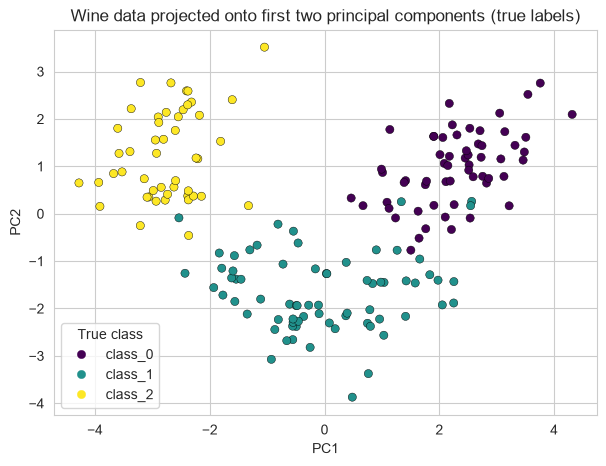

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance by PC1 and PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", s=35, edgecolor="k", linewidth=0.3)
plt.legend(handles=sc.legend_elements()[0], labels=list(wine.target_names), title="True class")
plt.title("Wine data projected onto first two principal components (true labels)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

Indeed, even in two dimensions, the three varieties are situated rather far apart, with some overlap at the boundaries. This plot serves as my basis for comparison of the clusters below.

## Step 2: Hierarchical Clustering

I use `AgglomerativeClustering` with Ward linkage. Ward merges whichever pair of clusters adds the least within-cluster variance, which usually gives compact, evenly sized clusters. I try `n_clusters` from 2 to 6 and record the silhouette, homogeneity and completeness for each.

In [9]:
def evaluate(labels, X_data, y_true, ignore_noise=False):
    """Return silhouette, homogeneity, completeness. For DBSCAN the silhouette is
    computed only on the clustered (non-noise) points."""
    labels = np.asarray(labels)
    mask = labels != -1 if ignore_noise else np.ones(len(labels), bool)
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(X_data[mask], labels[mask]) if n_clusters > 1 else np.nan
    return sil, homogeneity_score(y_true, labels), completeness_score(y_true, labels)

hier_results = []
hier_labels = {}
for k in range(2, 7):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    hier_labels[k] = labels
    sil, hom, comp = evaluate(labels, X_scaled, y)
    hier_results.append({"n_clusters": k, "silhouette": sil, "homogeneity": hom, "completeness": comp})

hier_df = pd.DataFrame(hier_results).round(3)
hier_df

,n_clusters,silhouette,homogeneity,completeness
0,2,0.267,0.444,0.774
1,3,0.277,0.790,0.783
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576
4,6,0.180,0.835,0.553


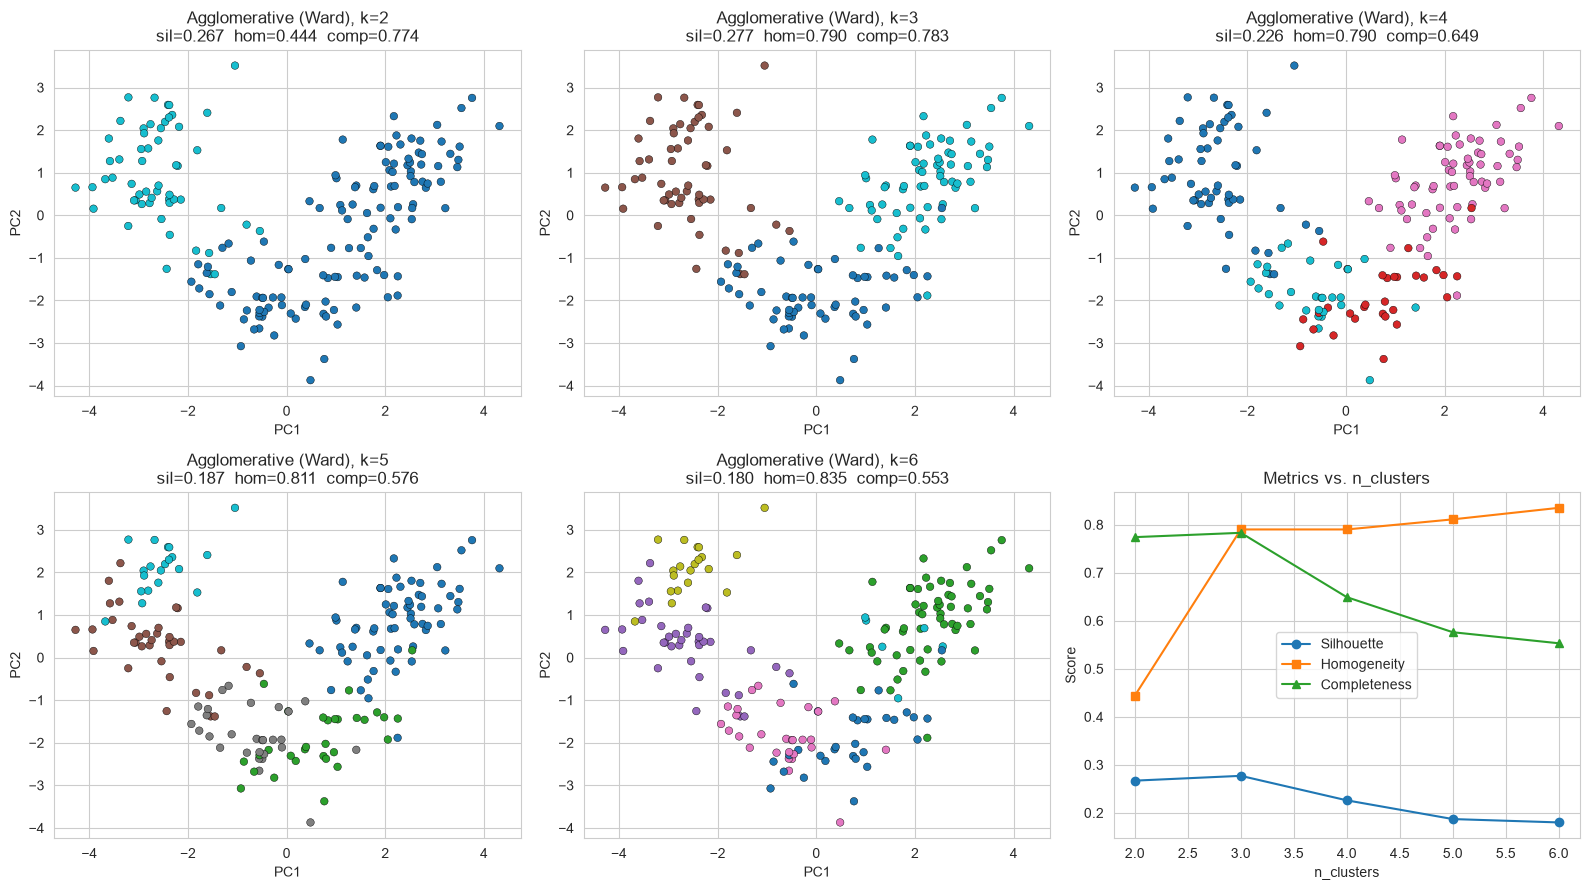

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for ax, k in zip(axes, range(2, 7)):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels[k], cmap="tab10", s=30, edgecolor="k", linewidth=0.3)
    r = hier_df.set_index("n_clusters").loc[k]
    ax.set_title(f"Agglomerative (Ward), k={k}\nsil={r.silhouette:.3f}  hom={r.homogeneity:.3f}  comp={r.completeness:.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

axes[-1].plot(hier_df.n_clusters, hier_df.silhouette, "o-", label="Silhouette")
axes[-1].plot(hier_df.n_clusters, hier_df.homogeneity, "s-", label="Homogeneity")
axes[-1].plot(hier_df.n_clusters, hier_df.completeness, "^-", label="Completeness")
axes[-1].set_xlabel("n_clusters"); axes[-1].set_ylabel("Score")
axes[-1].set_title("Metrics vs. n_clusters"); axes[-1].legend()
plt.tight_layout()
plt.show()

I was also interested in seeing the importance of the linkage technique, so I used k = 3 with other linkage techniques.

In [11]:
link_rows = []
for link in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_scaled)
    sil, hom, comp = evaluate(labels, X_scaled, y)
    link_rows.append({"linkage": link, "silhouette": sil, "homogeneity": hom, "completeness": comp,
                      "cluster_sizes": np.bincount(labels).tolist()})
pd.DataFrame(link_rows).round(3)

,linkage,silhouette,homogeneity,completeness,cluster_sizes
0,ward,0.277,0.790,0.783,"[58, 56, 64]"
1,complete,0.204,0.616,0.613,"[69, 58, 51]"
2,average,0.158,0.010,0.093,"[174, 1, 3]"
3,single,0.183,0.019,0.175,"[174, 3, 1]"


**Observations:**
- **k = 3 is the best choice.** It has the highest silhouette of all the values I tried, and homogeneity and completeness are both about 0.79. That means the clusters line up closely with the three real cultivars.
- With k = 2, two cultivars end up in one cluster. Completeness stays high, but homogeneity falls to about 0.44.
- Going past 3 splits real classes into smaller pieces. Homogeneity barely moves, but completeness and silhouette both go down, so the extra clusters add nothing useful.
- Linkage matters a lot. Ward does best by a wide margin. Average and single linkage give one very large cluster plus a couple of tiny ones made from a few outlying wines. This is the "chaining" effect, and it makes those two methods a poor fit here.

### Dendrogram

Dendrogram displays all the merging steps of the hierarchy so that I don’t have to decide k beforehand. There are 178 nodes on the full tree and it is difficult to read; thus, I display it together with a truncated tree (last 30 mergings).

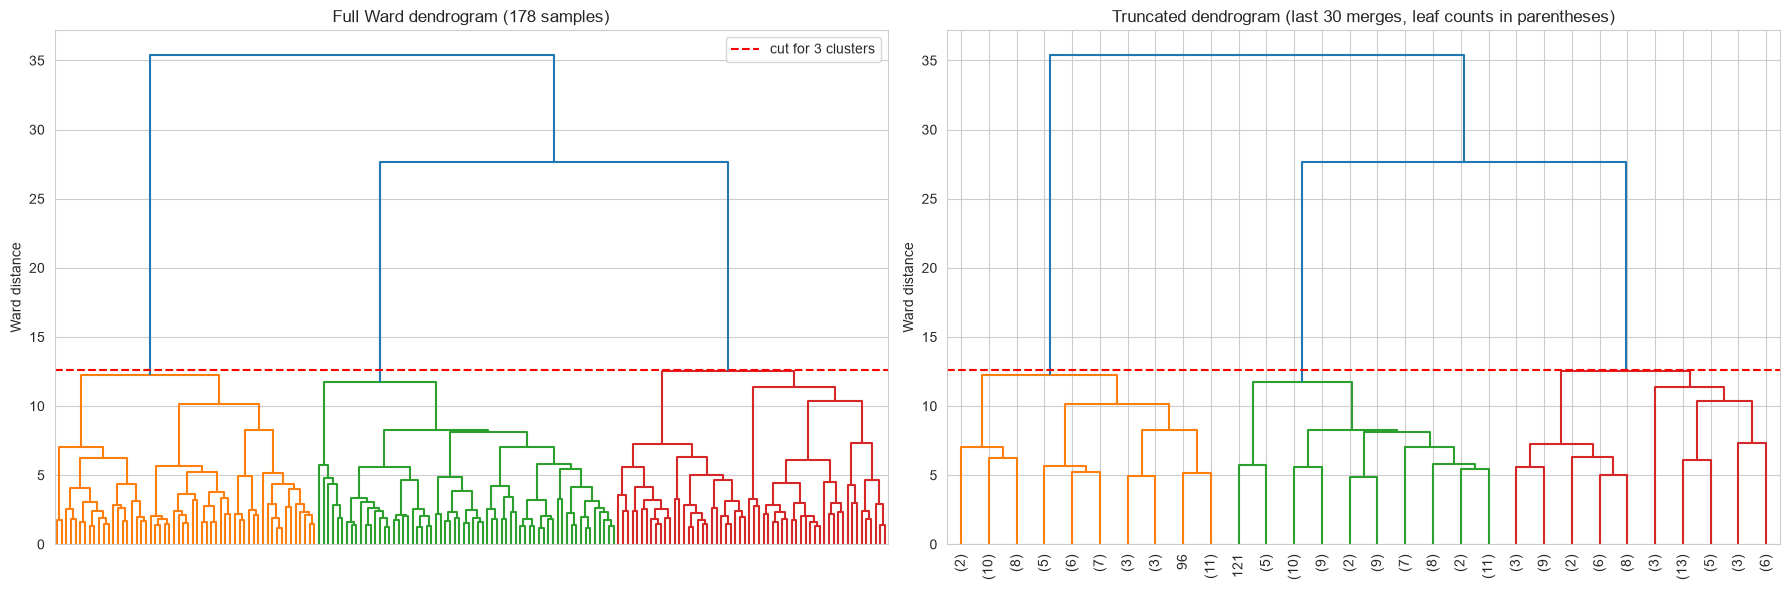

Heights of the last 6 merges: [11.38 11.72 12.23 12.57 27.65 35.4 ]


In [12]:
Z = linkage(X_scaled, method="ward")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
dendrogram(Z, ax=axes[0], no_labels=True, color_threshold=Z[-3, 2] + 0.01)
axes[0].axhline(y=Z[-3, 2] + 0.01, color="r", linestyle="--", label="cut for 3 clusters")
axes[0].set_title("Full Ward dendrogram (178 samples)")
axes[0].set_ylabel("Ward distance"); axes[0].legend()

dendrogram(Z, ax=axes[1], truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, color_threshold=Z[-3, 2] + 0.01)
axes[1].axhline(y=Z[-3, 2] + 0.01, color="r", linestyle="--")
axes[1].set_title("Truncated dendrogram (last 30 merges, leaf counts in parentheses)")
axes[1].set_ylabel("Ward distance")
plt.tight_layout()
plt.show()

print("Heights of the last 6 merges:", Z[-6:, 2].round(2))

**Interpreting the dendrogram:** The last mergers take place at heights considerably higher than any mergers below them. The largest leap in height occurs immediately following the three-way merge. The red dashed line runs through this gap and leaves three branches behind it. The long vertical gap preceding the merger suggests that the clusters being merged are distant from one another, indicating that there are three natural clusters according to the tree. This corresponds with the metrics mentioned above and also the three cultivars in reality. The branches below the cut-off point are short and close to each other, hence splitting even further (k=4, 5, 6) leads to clusters that are not clear-cut.

## Step 3: DBSCAN Clustering

DBSCAN doesn't need the number of clusters up front. It needs two settings:
- **`eps`**: the radius of a point's neighborhood.
- **`min_samples`**: how many points must fall inside that radius for a point to count as a core point.

Points that can't be reached from any core point are labeled noise (`-1`).

To get a sensible starting range for `eps`, I use a k-distance plot. I sort each point's distance to its k-th nearest neighbor and look for the "elbow" where the curve bends sharply upward.

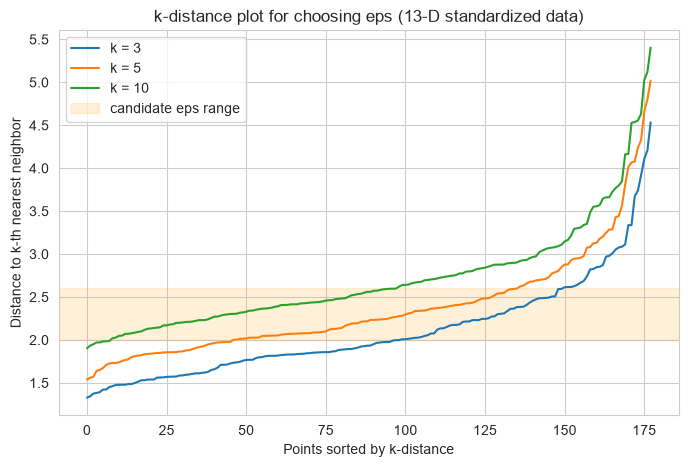

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for k in [3, 5, 10]:
    nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
    dist, _ = nn.kneighbors(X_scaled)
    ax.plot(np.sort(dist[:, -1]), label=f"k = {k}")
ax.axhspan(2.0, 2.6, color="orange", alpha=0.15, label="candidate eps range")
ax.set_xlabel("Points sorted by k-distance"); ax.set_ylabel("Distance to k-th nearest neighbor")
ax.set_title("k-distance plot for choosing eps (13-D standardized data)")
ax.legend()
plt.show()

The elbow lands somewhere between about 2.0 and 2.6, depending on k. Those are large values for standardized data, and the reason is the number of dimensions. In 13-D space points are spread far apart, so the neighborhood radius has to be large. Next I run a grid over `eps` and `min_samples`.

In [14]:
db_rows = []
for eps in [1.5, 1.8, 2.0, 2.2, 2.3, 2.4, 2.5, 2.6, 2.8, 3.0]:
    for ms in [3, 5, 8, 10]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int((labels == -1).sum())
        sil, hom, comp = evaluate(labels, X_scaled, y, ignore_noise=True)
        db_rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_clusters, "n_noise": n_noise,
                        "noise_%": round(100 * n_noise / len(labels), 1),
                        "silhouette": sil, "homogeneity": hom, "completeness": comp})

db_df = pd.DataFrame(db_rows).round(3)
pd.set_option("display.max_rows", 60)
db_df

,eps,min_samples,n_clusters,n_noise,noise_%,silhouette,homogeneity,completeness
0,1.5,3,8,147,82.6,0.331,0.189,0.251
1,1.5,5,0,178,100.0,NaN,0.000,1.000
2,1.5,8,0,178,100.0,NaN,0.000,1.000
3,1.5,10,0,178,100.0,NaN,0.000,1.000
4,1.8,3,8,90,50.6,0.312,0.532,0.375
5,1.8,5,7,118,66.3,0.246,0.354,0.307
6,1.8,8,1,170,95.5,NaN,0.057,0.337
7,1.8,10,0,178,100.0,NaN,0.000,1.000
8,2.0,3,5,64,36.0,0.211,0.442,0.372
9,2.0,5,5,85,47.8,0.240,0.362,0.325


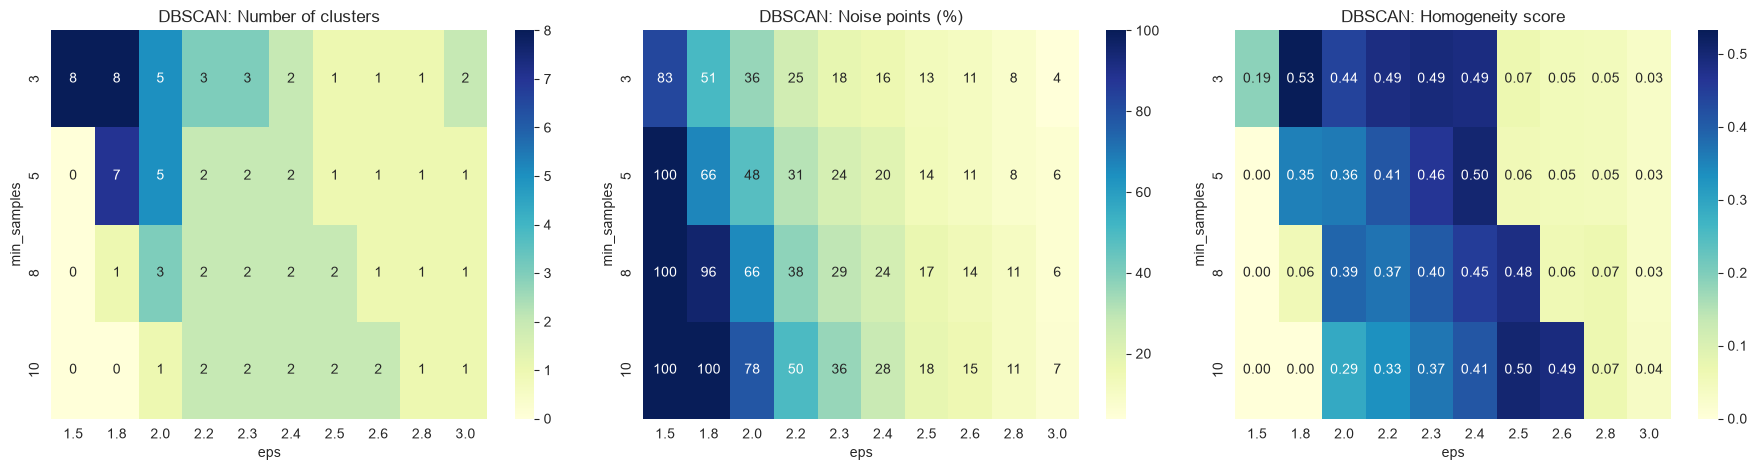

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, col, title in zip(axes, ["n_clusters", "noise_%", "homogeneity"],
                          ["Number of clusters", "Noise points (%)", "Homogeneity score"]):
    pivot = db_df.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(pivot, annot=True, fmt=".0f" if col != "homogeneity" else ".2f", cmap="YlGnBu", ax=ax)
    ax.set_title(f"DBSCAN: {title}")
plt.tight_layout()
plt.show()

The heatmaps show how sensitive DBSCAN is to its settings:
- **Small `eps` (≤ 1.5)**: almost every point is noise. The neighborhoods are too small to find any dense region in 13-D.
- **Large `eps` (≥ 2.6 with small `min_samples`)**: neighborhoods grow until everything links together into one cluster. Homogeneity falls close to 0.
- **Higher `min_samples`** makes the core-point test harder to pass. More points become noise, and the range of `eps` that gives more than one cluster moves to the right.
- The useful range is narrow, about `eps` 2.2–2.5. Even there DBSCAN mostly finds **2** clusters. It reaches 3 clusters only at a few settings and labels a good share of points as noise.

Below I plot a set of settings that show these different behaviors, with noise points drawn as black X markers.

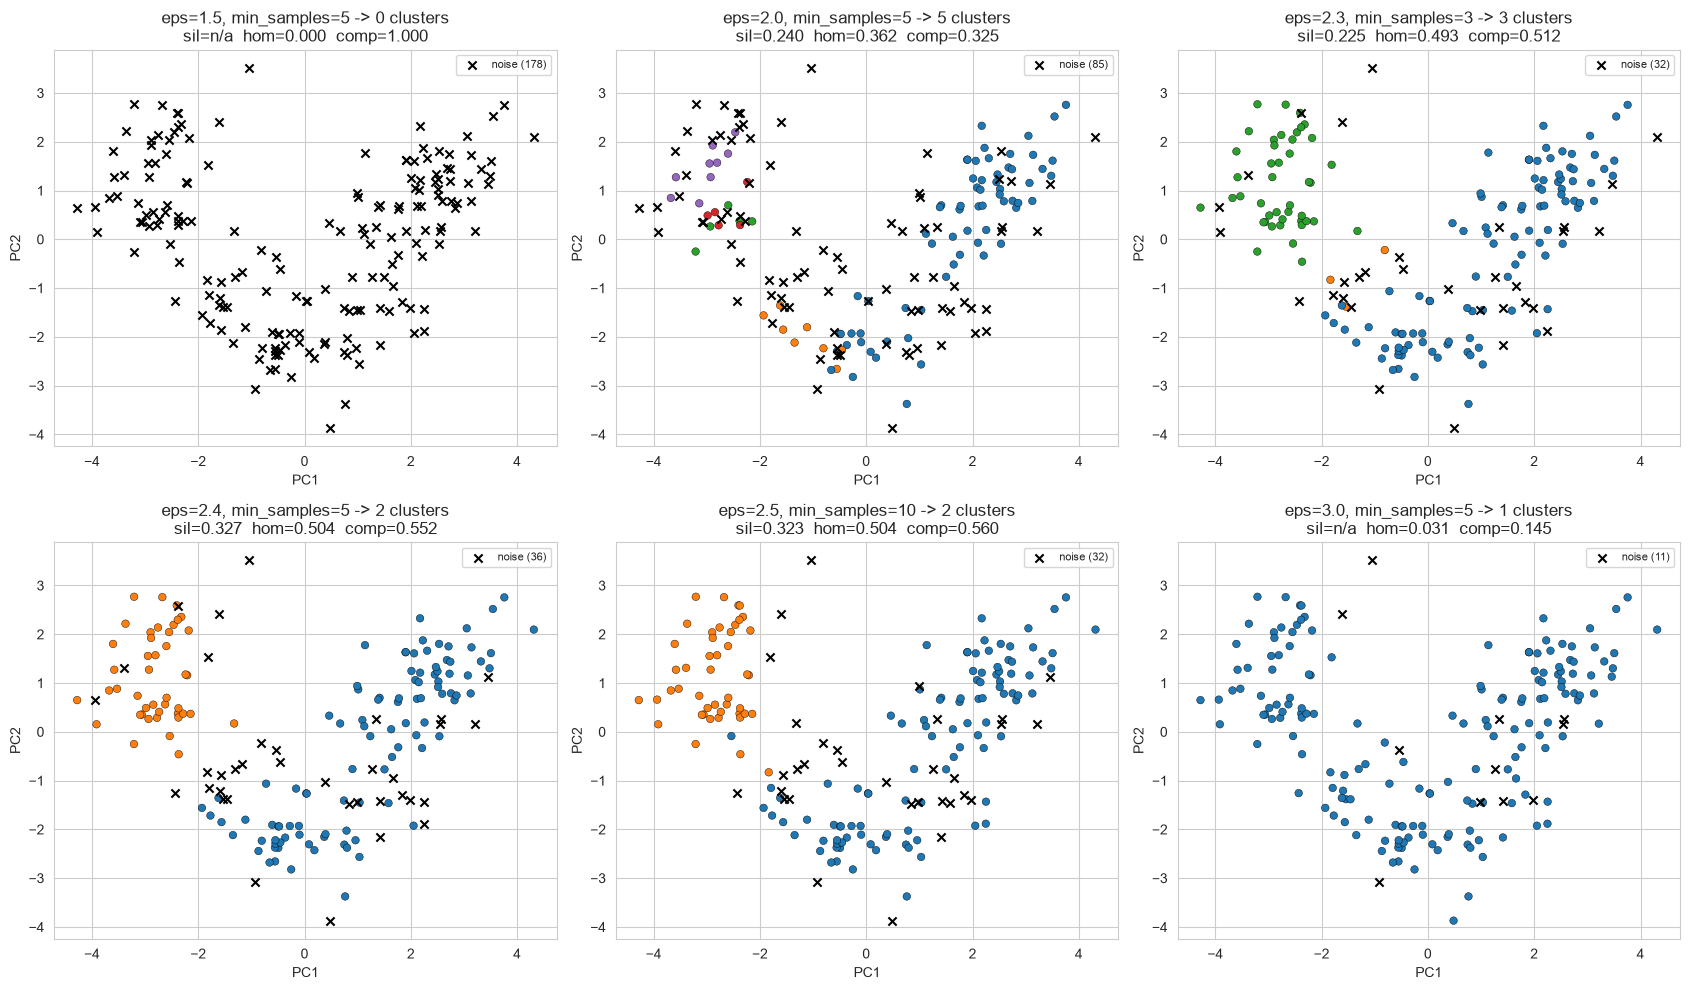

In [16]:
def plot_dbscan(ax, labels, title):
    noise = labels == -1
    ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap="tab10", s=30,
               edgecolor="k", linewidth=0.3, vmin=0, vmax=9)
    ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="black", marker="x", s=35, label=f"noise ({noise.sum()})")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(loc="upper right", fontsize=8)

settings = [(1.5, 5), (2.0, 5), (2.3, 3), (2.4, 5), (2.5, 10), (3.0, 5)]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (eps, ms) in zip(axes.ravel(), settings):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    n_c = len(set(labels)) - (1 if -1 in labels else 0)
    sil, hom, comp = evaluate(labels, X_scaled, y, ignore_noise=True)
    sil_txt = "n/a" if np.isnan(sil) else f"{sil:.3f}"
    plot_dbscan(ax, labels, f"eps={eps}, min_samples={ms} -> {n_c} clusters\n"
                            f"sil={sil_txt}  hom={hom:.3f}  comp={comp:.3f}")
plt.tight_layout()
plt.show()

### Selecting a DBSCAN configuration and reporting metrics

In order to select a particular configuration, I retain only those which have been able to cluster at least 2 points and not marked more than 30% of the points as noise. Amongst these configurations, I pick the one with the highest V-measure score (which is the harmonic mean of homogeneity and completeness). I made this choice since silhouette score on its own will favor configurations that reject all data as noise except for a few clusters.

In [17]:
cand = db_df[(db_df.n_clusters >= 2) & (db_df["noise_%"] <= 30)].copy()
cand["v_measure"] = 2 * cand.homogeneity * cand.completeness / (cand.homogeneity + cand.completeness)
best = cand.sort_values("v_measure", ascending=False).iloc[0]
best_eps, best_ms = best.eps, int(best.min_samples)
print(f"Selected DBSCAN parameters: eps={best_eps}, min_samples={best_ms}")
cand.sort_values("v_measure", ascending=False).head(8)

Selected DBSCAN parameters: eps=2.5, min_samples=10


,eps,min_samples,n_clusters,n_noise,noise_%,silhouette,homogeneity,completeness,v_measure
27,2.5,10,2,32,18.0,0.323,0.504,0.560,0.530526
21,2.4,5,2,36,20.2,0.327,0.504,0.552,0.526909
31,2.6,10,2,27,15.2,0.308,0.489,0.558,0.521226
20,2.4,3,2,28,15.7,0.314,0.487,0.549,0.516145
26,2.5,8,2,30,16.9,0.318,0.484,0.545,0.512692
16,2.3,3,3,32,18.0,0.225,0.493,0.512,0.502320
12,2.2,3,3,44,24.7,0.073,0.486,0.481,0.483487
17,2.3,5,2,42,23.6,0.331,0.462,0.492,0.476528


Clusters found      : 2
Noise points        : 32 of 178
Silhouette Score    : 0.323   (computed on non-noise points)
Homogeneity Score   : 0.504
Completeness Score  : 0.560


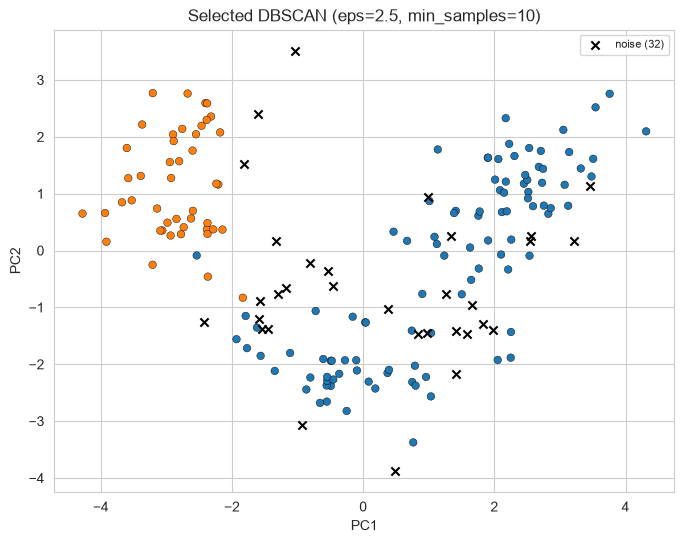


Crosstab of DBSCAN clusters vs. true class (-1 = noise):


True class,class_0,class_1,class_2
DBSCAN cluster,,,
-1,3,25,4
0,56,45,0
1,0,1,44


In [18]:
db_labels = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_scaled)
db_sil, db_hom, db_comp = evaluate(db_labels, X_scaled, y, ignore_noise=True)
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)

print(f"Clusters found      : {n_clusters_db}")
print(f"Noise points        : {(db_labels == -1).sum()} of {len(db_labels)}")
print(f"Silhouette Score    : {db_sil:.3f}   (computed on non-noise points)")
print(f"Homogeneity Score   : {db_hom:.3f}")
print(f"Completeness Score  : {db_comp:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
plot_dbscan(ax, db_labels, f"Selected DBSCAN (eps={best_eps}, min_samples={best_ms})")
plt.show()

print("\nCrosstab of DBSCAN clusters vs. true class (-1 = noise):")
pd.crosstab(pd.Series(db_labels, name="DBSCAN cluster"),
            pd.Series(wine.target_names[y], name="True class"))

The crosstab shows what DBSCAN is doing. With `eps=2.5` and `min_samples=10` it finds only **2 clusters** and labels **32 wines (18%) as noise**. `class_2` comes out almost perfectly as its own cluster (44 of 48 wines). `class_0` and `class_1`, however, are joined into one large cluster (56 + 45 wines). Most of the noise points (25 of 32) are `class_1` wines, the cultivar that sits between the other two in the PCA plot. All three cultivars do touch each other at the edges, so in 13-D there's no low-density gap between them for DBSCAN to split along.

### Extra experiment: DBSCAN on the 2-D PCA projection

I was curious whether reducing the dimensions first would help DBSCAN, since density-based methods tend to do better in fewer dimensions. As a side test I ran DBSCAN on the 2 principal components. It isn't part of the main comparison, because the hierarchical model uses all 13 features.

Best on PCA-2D:
eps              0.800
min_samples     15.000
n_clusters       3.000
n_noise         33.000
silhouette       0.660
homogeneity      0.754
completeness     0.598
v_measure        0.667


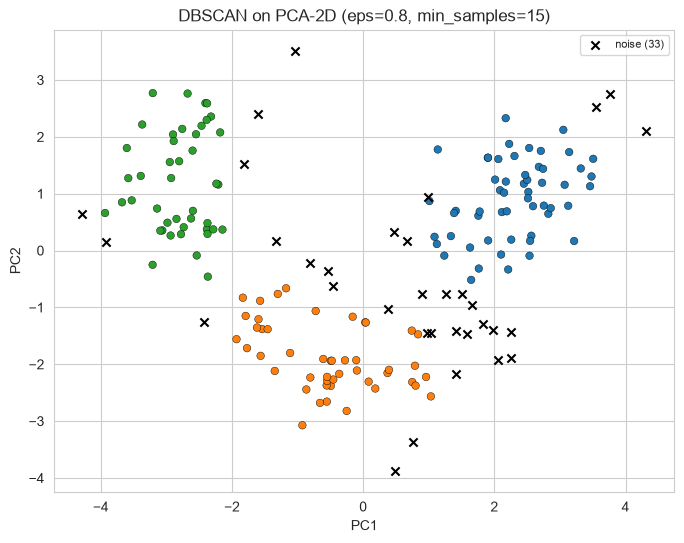

In [19]:
pca_rows = []
for eps in [0.4, 0.5, 0.6, 0.7, 0.8]:
    for ms in [5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        n_c = len(set(labels)) - (1 if -1 in labels else 0)
        sil, hom, comp = evaluate(labels, X_pca, y, ignore_noise=True)
        pca_rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_c,
                         "n_noise": int((labels == -1).sum()),
                         "silhouette": sil, "homogeneity": hom, "completeness": comp})
pca_db = pd.DataFrame(pca_rows).round(3)
pca_db["v_measure"] = (2 * pca_db.homogeneity * pca_db.completeness /
                       (pca_db.homogeneity + pca_db.completeness)).round(3)
best_pca = pca_db[pca_db.n_clusters >= 2].sort_values("v_measure", ascending=False).iloc[0]
print("Best on PCA-2D:"); print(best_pca.to_string())

lbl = DBSCAN(eps=best_pca.eps, min_samples=int(best_pca.min_samples)).fit_predict(X_pca)
fig, ax = plt.subplots(figsize=(8, 6))
plot_dbscan(ax, lbl, f"DBSCAN on PCA-2D (eps={best_pca.eps}, min_samples={int(best_pca.min_samples)})")
plt.show()

DBSCAN run in 2 dimensions offers an improved compromise between homogeneity and completeness compared to when it was run on the full set of 13 dimensions. This lends some credence to the notion that the number of dimensions was a key factor that affected DBSCAN’s performance. There are still some instances where the data points will be classified as noise.

## Step 4: Analysis and Insights

### Side-by-side comparison

In [20]:
h_labels = hier_labels[3]
h_sil, h_hom, h_comp = evaluate(h_labels, X_scaled, y)

summary = pd.DataFrame({
    "Agglomerative (Ward, k=3)": [3, 0, h_sil, h_hom, h_comp],
    f"DBSCAN (eps={best_eps}, min_samples={best_ms})": [n_clusters_db, int((db_labels == -1).sum()), db_sil, db_hom, db_comp],
}, index=["Clusters", "Noise points", "Silhouette", "Homogeneity", "Completeness"]).T
summary[["Silhouette", "Homogeneity", "Completeness"]] = summary[["Silhouette", "Homogeneity", "Completeness"]].astype(float).round(3)
summary

,Clusters,Noise points,Silhouette,Homogeneity,Completeness
"Agglomerative (Ward, k=3)",3.0,0.0,0.277,0.790,0.783
"DBSCAN (eps=2.5, min_samples=10)",2.0,32.0,0.323,0.504,0.560


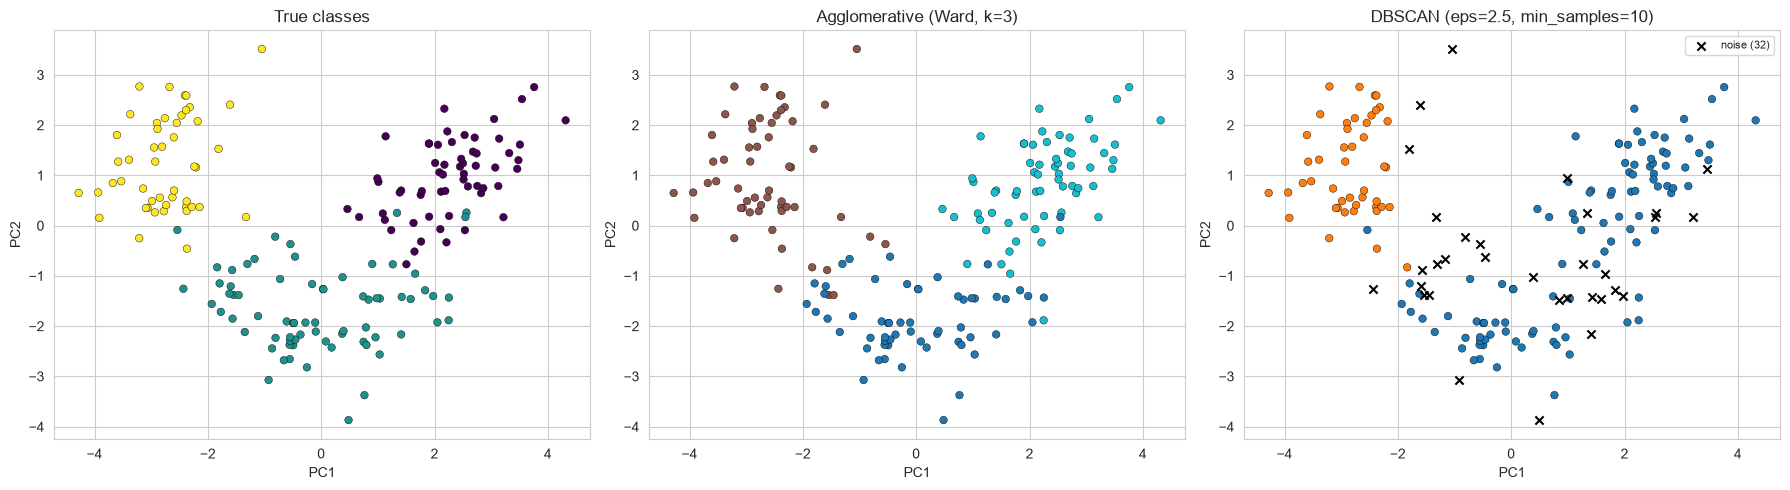

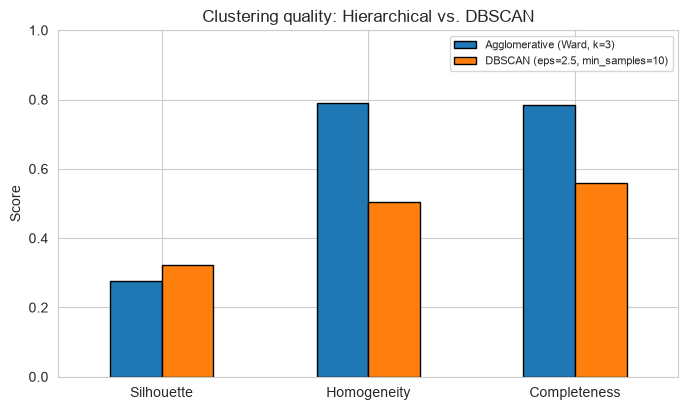

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", s=30, edgecolor="k", linewidth=0.3)
axes[0].set_title("True classes")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=h_labels, cmap="tab10", s=30, edgecolor="k", linewidth=0.3)
axes[1].set_title("Agglomerative (Ward, k=3)")
plot_dbscan(axes[2], db_labels, f"DBSCAN (eps={best_eps}, min_samples={best_ms})")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

metrics = summary[["Silhouette", "Homogeneity", "Completeness"]]
metrics.T.plot(kind="bar", figsize=(8, 4.5), rot=0, edgecolor="k")
plt.title("Clustering quality: Hierarchical vs. DBSCAN"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.legend(loc="upper right", fontsize=8)
plt.show()

### Comparison of results

On this particular dataset, it is evident that Ward hierarchical clustering performs better than DBSCAN. For example, with k = 3, the results obtained from clustering the dataset are good with the homogeneity and completeness score being approximately 0.79 each, and all the wines clustered into their respective groups. The best result obtained from DBSCAN was achieved with eps = 2.5 and min_samples = 10, where only two clusters were formed with 32 data points marked as noise and with low scores of homogeneity (0.504) and completeness (0.560). Although the silhouette value of DBSCAN is 0.323 compared to 0.277 for Ward hierarchical clustering, the silhouette value is calculated using the points that are not marked as noise.

### How the parameters shaped the outcome

For hierarchical clustering the main choices were `n_clusters` and the linkage method. The metrics and the dendrogram both pointed to k = 3, and every other value either merged cultivars or split them into small pieces. Linkage mattered even more than k. Ward gave balanced, meaningful clusters, while average and single linkage produced one huge cluster plus a few outliers.

DBSCAN was far more sensitive. Changing `eps` by just 0.2–0.3 flipped the result from "nearly everything is noise" to "everything is one cluster." Raising `min_samples` made the algorithm stricter: more points became noise, and the useful `eps` range moved higher. The k-distance plot was a good starting point, but I still needed the grid search to find a usable setting. Even then, the range that gave more than one cluster was narrow.

### Strengths and weaknesses

**Hierarchical (Agglomerative) clustering**
- *Strengths:* The dendrogram gives a visual reason for choosing the number of clusters. The results are deterministic. Ward linkage suits data like this, where the groups are roughly round and similar in size.
- *Weaknesses:* I still have to choose where to cut the tree, so k is effectively a parameter. It has no idea of noise, so every outlier gets forced into a cluster. It needs O(n²) memory, which is fine for 178 rows but would be a problem on large datasets. The result also depends heavily on the linkage method.

**DBSCAN**
- *Strengths:* It doesn't need the number of clusters ahead of time. It can find clusters of any shape. It flags outliers as noise on its own, which is very useful when outliers matter (for example, a mislabeled or unusual wine).
- *Weaknesses:* It is very sensitive to `eps` and `min_samples`. It struggles in higher dimensions, where distances become more similar to each other. It assumes clusters are separated by low-density gaps, and the Wine data doesn't have strong gaps between cultivars. A single global `eps` also can't handle clusters that have different densities.

### Takeaway

The Wine data is made of compact, roughly round groups that touch at their edges, so it suits a variance-based method like Ward much better than a density-based one. DBSCAN would be the better choice for data with oddly shaped clusters and clear empty space between them, or when finding outliers is part of the goal. The PCA side experiment showed that lowering the number of dimensions helps DBSCAN noticeably. Even so, I would still pick hierarchical clustering for this dataset.